# Implementación de un modelo de deep learning

## Alfredo Alejandro Soto Herrera - A01711368

### Modelo 1 - CNN

### Configuración y carga del dataset

In [1]:
import os, sys, json, zipfile, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

# Parámetros
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = int(os.environ.get("EPOCHS", 60))

keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:", gpus if gpus else "NO")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
IN_COLAB = "google.colab" in sys.modules
WORK_DIR = "/content" if IN_COLAB else os.path.abspath("./work_model")
os.makedirs(WORK_DIR, exist_ok=True)

ZIP_PATH = "/content/drive/MyDrive/car_dataset_processed.zip"
DATA_DIR = os.path.join(WORK_DIR, "car_data")
SAVE_DIR = "/content/drive/MyDrive/car_models" if IN_COLAB else os.path.join(WORK_DIR, "models")

env_dir = os.environ.get("CAR_PROC_DIR")
if env_dir:
    DATA_DIR = env_dir
elif not os.path.isdir(os.path.join(DATA_DIR, "train")):
    if IN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

for root, dirs, _ in os.walk(DATA_DIR):
    if "train" in dirs and "val" in dirs and "test" in dirs:
        DATA_DIR = root
        break

os.makedirs(SAVE_DIR, exist_ok=True)
print("DATA_DIR:", DATA_DIR)
print("Contenido:", sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
DATA_DIR: /content/car_data
Contenido: ['class_weights.json', 'splits.csv', 'test', 'train', 'val']


### Pipeline de datos

In [3]:
common = dict(image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="int")

train_raw = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "train"), shuffle=True, seed=SEED, **common)
val_raw   = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "val"),   shuffle=False, **common)
test_raw  = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "test"),  shuffle=False, **common)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
val_paths, test_paths = val_raw.file_paths, test_raw.file_paths   # los guardamos para el análisis de errores

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.cache().prefetch(AUTOTUNE)
val_ds   = val_raw.cache().prefetch(AUTOTUNE)
test_ds  = test_raw.cache().prefetch(AUTOTUNE)

print("Clases:", class_names)

Found 1267 files belonging to 10 classes.
Found 270 files belonging to 10 classes.
Found 270 files belonging to 10 classes.
Clases: ['Audi_R8', 'Audi_RS5', 'BMW_M3', 'BMW_M5', 'Chevrolet_Camaro', 'Ford_Mustang', 'Mercedes_AMG_GT', 'Nissan_GT_R', 'Porsche_911', 'Toyota_Supra']


In [4]:
def labels_of(ds):
    return np.concatenate([y.numpy() for _, y in ds])

y_train, y_val, y_test = labels_of(train_ds), labels_of(val_ds), labels_of(test_ds)
summary = pd.DataFrame({
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "val": np.bincount(y_val, minlength=NUM_CLASSES),
    "test": np.bincount(y_test, minlength=NUM_CLASSES),
}, index=class_names)
summary.loc["TOTAL"] = summary.sum()
display(summary)

,train,val,test
Audi_R8,153,31,30
Audi_RS5,82,17,19
BMW_M3,148,33,32
BMW_M5,163,35,35
Chevrolet_Camaro,126,25,25
Ford_Mustang,118,27,24
Mercedes_AMG_GT,94,21,24
Nissan_GT_R,123,26,25
Porsche_911,124,25,26
Toyota_Supra,136,30,30


### Data augmentation

Data augmentation genera variaciones aleatorias de cada foto en cada época, de forma que el modelo casi nunca ve exactamente la misma imagen dos veces.

- Volteo horizontal
- Rotación y zoom leves
- Contraste y brillo

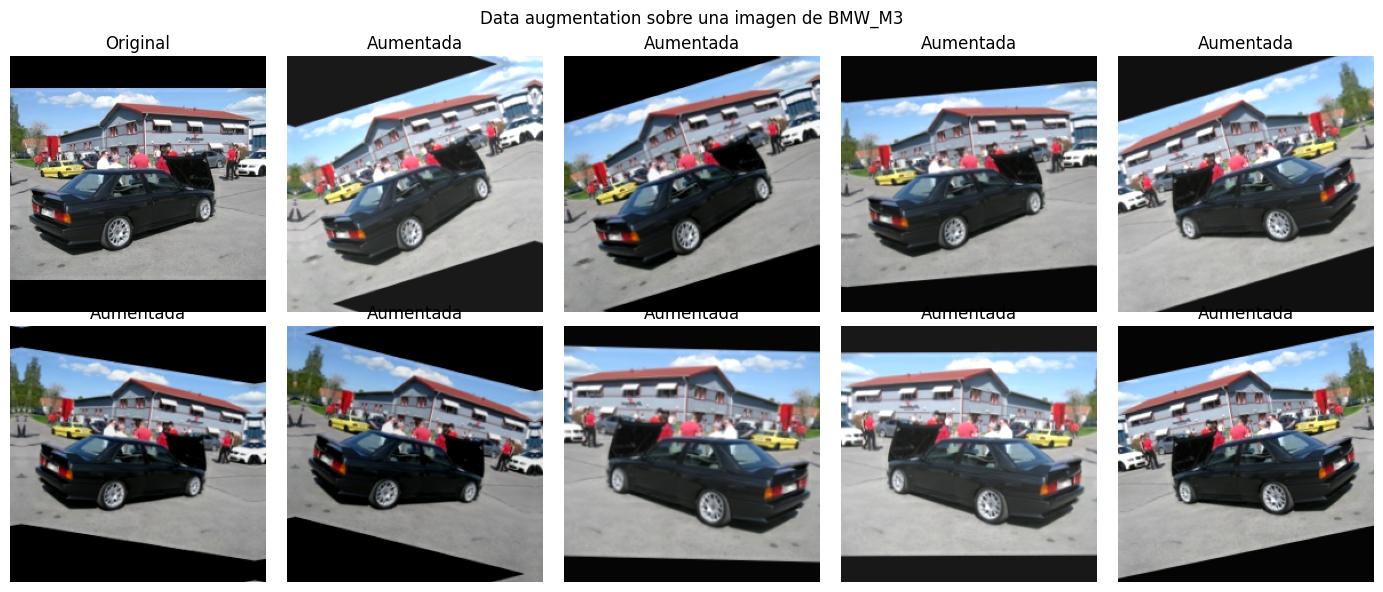

In [5]:
def make_augmentation(flip=True, rotation=0.05, zoom=0.10, contrast=0.10, brightness=0.10):
    aug = []
    if flip:
        aug.append(layers.RandomFlip("horizontal"))
    if rotation:
        aug.append(layers.RandomRotation(rotation))
    if zoom:
        aug.append(layers.RandomZoom(zoom))
    if contrast:
        aug.append(layers.RandomContrast(contrast))
    if brightness:
        aug.append(layers.RandomBrightness(brightness, value_range=(0, 255)))
    return keras.Sequential(aug, name="augmentation")

augmentation = make_augmentation()

# Visualizamos 8 versiones aumentadas de una misma foto
images, labels = next(iter(train_raw))
img = images[0:1]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes[0, 0].imshow(img[0].numpy().astype("uint8")); axes[0, 0].set_title("Original")
for ax in axes.ravel()[1:]:
    ax.imshow(np.clip(augmentation(img, training=True)[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title("Aumentada")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle(f"Data augmentation sobre una imagen de {class_names[labels[0]]}"); plt.tight_layout(); plt.show()

### Arquitectura de la CNN

- Rescaling(1/255): Escala los píxeles a 0-1.

- Conv - BatchNorm - ReLU - MaxPool: Filtros 32, 64, 128 y 256.

- GlobalAveragePooling2D: Reduce el número de parámetros.

- Dropout(0, 4): Apaga neuronas para evitar memorización.

- Dense(10, softmax): Genera la probabilidad por clase.

In [6]:
def build_cnn(filters=(32, 64, 128, 256), dropout=0.4, aug=True, l2=0.0, name="cnn_base"):
    reg = keras.regularizers.l2(l2) if l2 else None
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inputs
    if aug:
        x = augmentation(x)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)

model = build_cnn()
model.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 392,426 (1.50 MB)

 Trainable params: 391,466 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

### Entrenamiento

- Optimizador Adam, learning rate 1e-3.
- Pérdida sparse_categorical_crossentropy.
- Métrica: accuracy.
- EarlyStopping con paciencia 12 sobre val_loss y restaura los mejores pesos.
- ReduceLROnPlateau por si la validación se estanca.

In [7]:
LEARNING_RATE = 1e-3

model.compile(
    optimizer=keras.optimizers.Adam(LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)

Epoch 1/60
40/40 - 15s - 382ms/step - accuracy: 0.1634 - loss: 2.4569 - val_accuracy: 0.1630 - val_loss: 2.2615 - learning_rate: 0.0010
Epoch 2/60
40/40 - 5s - 121ms/step - accuracy: 0.1910 - loss: 2.3146 - val_accuracy: 0.1926 - val_loss: 2.2942 - learning_rate: 0.0010
Epoch 3/60
40/40 - 5s - 126ms/step - accuracy: 0.2060 - loss: 2.2804 - val_accuracy: 0.1889 - val_loss: 2.3965 - learning_rate: 0.0010
Epoch 4/60
40/40 - 5s - 132ms/step - accuracy: 0.2036 - loss: 2.2258 - val_accuracy: 0.1926 - val_loss: 2.3422 - learning_rate: 0.0010
Epoch 5/60
40/40 - 5s - 131ms/step - accuracy: 0.2257 - loss: 2.2125 - val_accuracy: 0.1741 - val_loss: 2.3493 - learning_rate: 0.0010
Epoch 6/60
40/40 - 5s - 121ms/step - accuracy: 0.2289 - loss: 2.2048 - val_accuracy: 0.2111 - val_loss: 2.2578 - learning_rate: 0.0010
Epoch 7/60
40/40 - 5s - 131ms/step - accuracy: 0.2305 - loss: 2.1556 - val_accuracy: 0.2370 - val_loss: 2.2641 - learning_rate: 0.0010
Epoch 8/60
40/40 - 10s - 260ms/step - accuracy: 0.2313

Curvas de aprendizaje:

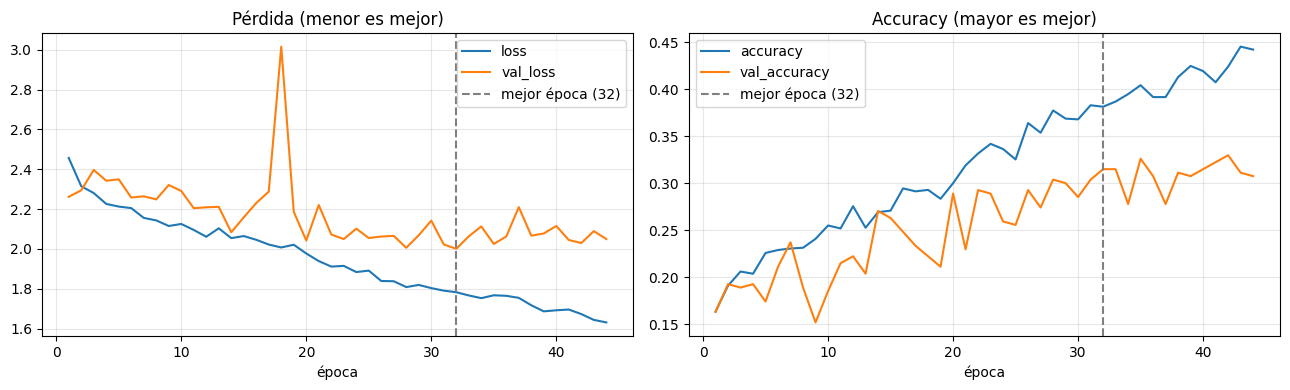

Mejor época según val_loss: 32  |  épocas entrenadas: 44


In [8]:
hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
best_epoch = int(hist["val_loss"].idxmin())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hist[["loss", "val_loss"]].plot(ax=ax[0], title="Pérdida (menor es mejor)", xlabel="época")
hist[["accuracy", "val_accuracy"]].plot(ax=ax[1], title="Accuracy (mayor es mejor)", xlabel="época")
for a in ax:
    a.axvline(best_epoch, color="gray", ls="--", label=f"mejor época ({best_epoch})")
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Mejor época según val_loss: {best_epoch}  |  épocas entrenadas: {len(hist)}")

Métricas en train y validación:

In [9]:
tr_loss, tr_acc = model.evaluate(train_ds, verbose=0)
va_loss, va_acc = model.evaluate(val_ds, verbose=0)

y_val_pred_prob = model.predict(val_ds, verbose=0)
y_val_pred = y_val_pred_prob.argmax(axis=1)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")

metrics = pd.DataFrame({"loss": [tr_loss, va_loss], "accuracy": [tr_acc, va_acc]}, index=["train", "val"]).round(4)
display(metrics)
print(f"Macro-F1 en validación: {val_macro_f1:.4f}")

gap = tr_acc - va_acc
print(f"\nBrecha de accuracy train - val: {gap:+.3f}")
if va_acc < 0.60 and gap < 0.10:
    print("Regla práctica -> accuracy bajo en ambos conjuntos y brecha pequeña: el modelo está limitado (subajuste / sesgo alto).")
elif gap >= 0.15:
    print("Regla práctica -> brecha grande entre train y val: señal de sobreajuste (varianza alta).")
else:
    print("Regla práctica -> brecha moderada")

,loss,accuracy
train,1.7289,0.4065
val,2.0005,0.3148


Macro-F1 en validación: 0.2271

Brecha de accuracy train - val: +0.092
Regla práctica -> accuracy bajo en ambos conjuntos y brecha pequeña: el modelo está limitado (subajuste / sesgo alto).


Métricas por clase:

,precision,recall,f1-score,support
Audi_R8,0.299,0.742,0.426,31.000
Audi_RS5,0.000,0.000,0.000,17.000
BMW_M3,0.300,0.182,0.226,33.000
BMW_M5,0.448,0.857,0.588,35.000
Chevrolet_Camaro,0.269,0.280,0.275,25.000
Ford_Mustang,0.188,0.111,0.140,27.000
Mercedes_AMG_GT,0.333,0.048,0.083,21.000
Nissan_GT_R,0.125,0.038,0.059,26.000
Porsche_911,0.333,0.120,0.176,25.000
Toyota_Supra,0.250,0.367,0.297,30.000


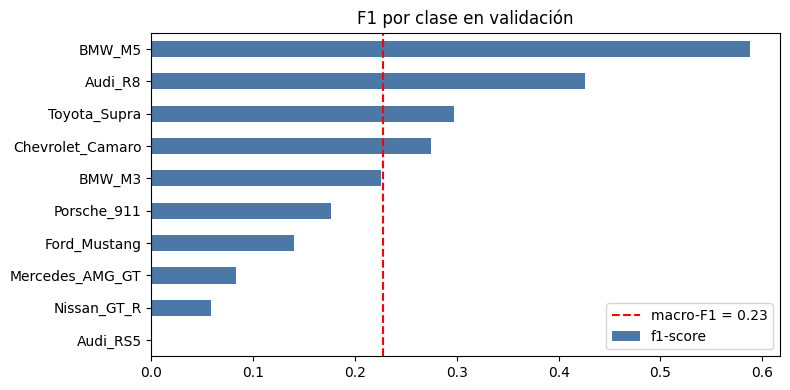

In [10]:
report = classification_report(y_val, y_val_pred, target_names=class_names, digits=3, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.round(3)
display(report_df)

per_class = report_df.loc[class_names, "f1-score"].sort_values()
ax = per_class.plot.barh(figsize=(8, 4), color="#4C78A8", title="F1 por clase en validación")
ax.axvline(val_macro_f1, color="red", ls="--", label=f"macro-F1 = {val_macro_f1:.2f}")
ax.legend(); plt.tight_layout(); plt.show()

Matriz de confusión:

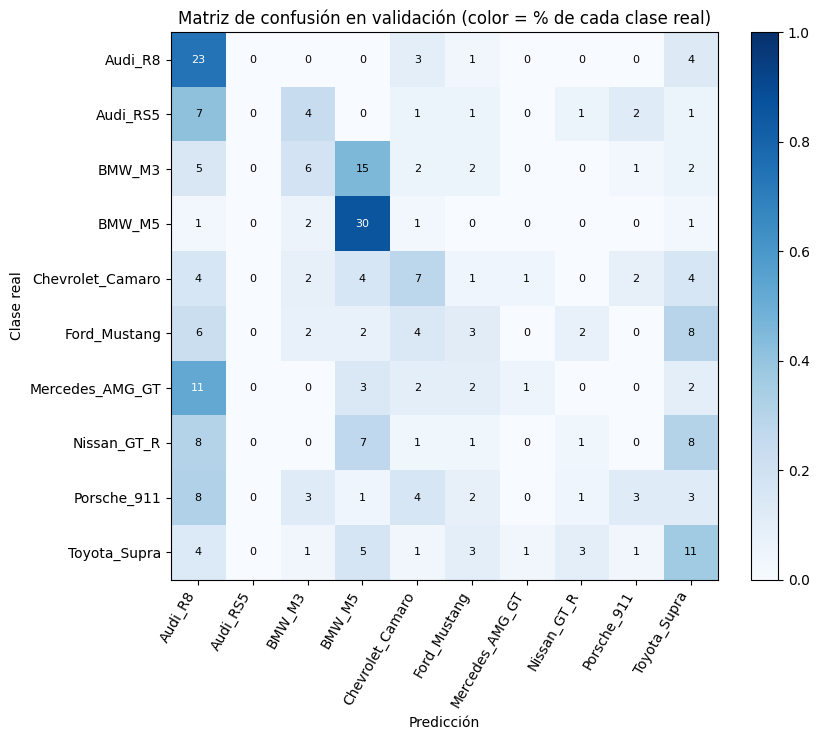

Confusiones más frecuentes:


,clase real,predicha como,veces
11,BMW_M3,BMW_M5,15
33,Mercedes_AMG_GT,Audi_R8,11
42,Nissan_GT_R,Toyota_Supra,8
38,Nissan_GT_R,Audi_R8,8
32,Ford_Mustang,Toyota_Supra,8
43,Porsche_911,Audi_R8,8
39,Nissan_GT_R,BMW_M5,7
3,Audi_RS5,Audi_R8,7


In [11]:
cm = confusion_matrix(y_val, y_val_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=60, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=8,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicción"); ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión en validación (color = % de cada clase real)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

off = [(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
off = pd.DataFrame(off, columns=["clase real", "predicha como", "veces"]).sort_values("veces", ascending=False).head(8)
print("Confusiones más frecuentes:")
display(off)

In [16]:
RUN_TEST_EVAL = True

if RUN_TEST_EVAL:
    te_loss, te_acc = model.evaluate(test_ds, verbose=0)
    y_test_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
    print(f"TEST -> loss: {te_loss:.4f} | accuracy: {te_acc:.4f} | macro-F1: {f1_score(y_test, y_test_pred, average='macro'):.4f}")
    print(classification_report(y_test, y_test_pred, target_names=class_names, digits=3, zero_division=0))
else:
    print("Evaluación en test desactivada.")

TEST -> loss: 1.9237 | accuracy: 0.3296 | macro-F1: 0.2479
                  precision    recall  f1-score   support

         Audi_R8      0.329     0.900     0.482        30
        Audi_RS5      1.000     0.053     0.100        19
          BMW_M3      0.450     0.281     0.346        32
          BMW_M5      0.397     0.714     0.510        35
Chevrolet_Camaro      0.154     0.160     0.157        25
    Ford_Mustang      0.238     0.208     0.222        24
 Mercedes_AMG_GT      0.000     0.000     0.000        24
     Nissan_GT_R      0.222     0.160     0.186        25
     Porsche_911      0.333     0.038     0.069        26
    Toyota_Supra      0.382     0.433     0.406        30

        accuracy                          0.330       270
       macro avg      0.351     0.295     0.248       270
    weighted avg      0.342     0.330     0.271       270



### Análisis de errores

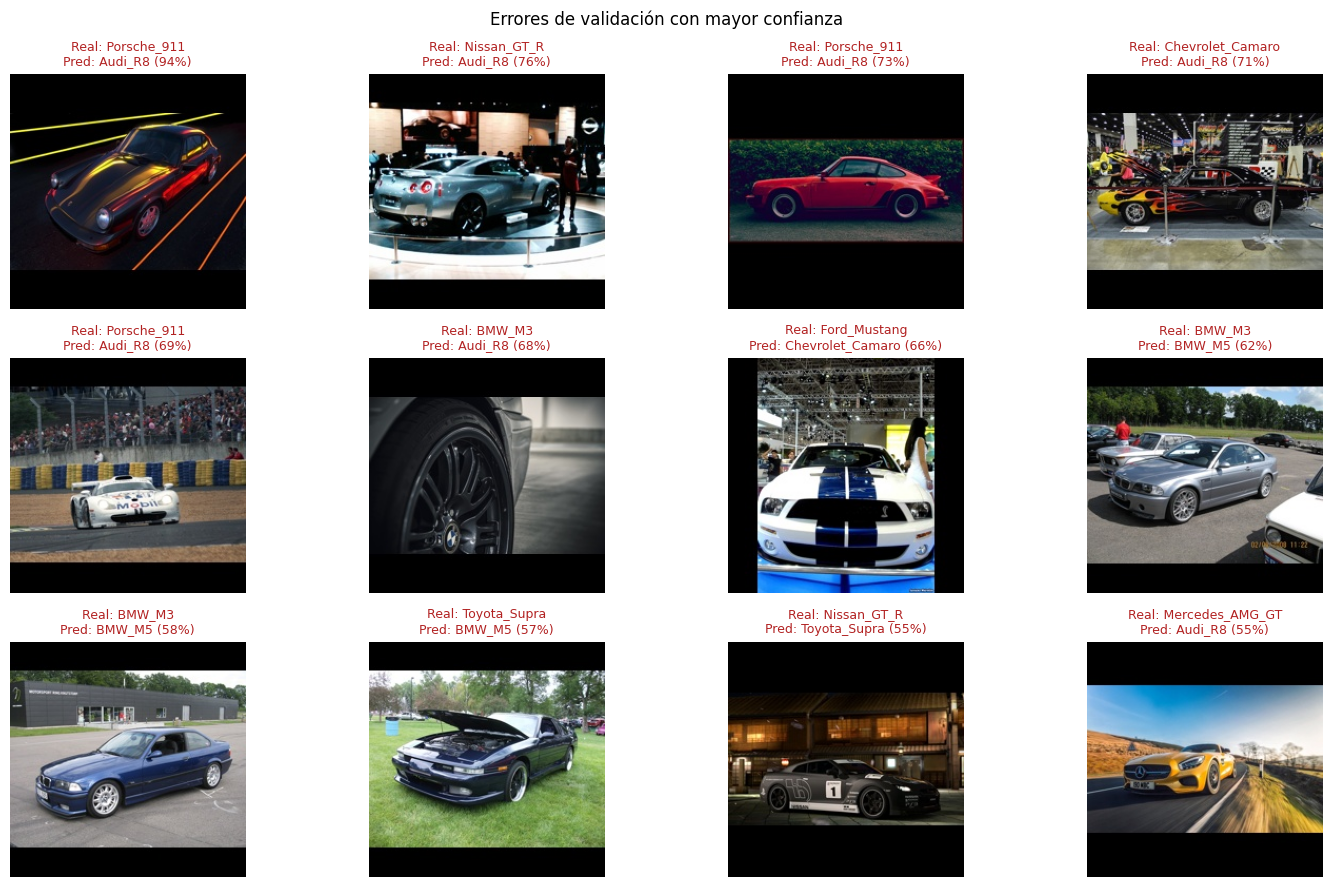

Errores totales en validación: 185 de 270


In [13]:
wrong = np.where(y_val_pred != y_val)[0]
conf = y_val_pred_prob.max(axis=1)
wrong = wrong[np.argsort(-conf[wrong])][:12]

fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(Image.open(val_paths[i]).convert("RGB"))
    ax.set_title(f"Real: {class_names[y_val[i]]}\nPred: {class_names[y_val_pred[i]]} ({conf[i]:.0%})", fontsize=9, color="firebrick")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Errores de validación con mayor confianza"); plt.tight_layout(); plt.show()
print(f"Errores totales en validación: {(y_val_pred != y_val).sum()} de {len(y_val)}")

Guardado

In [15]:
MODEL_PATH = os.path.join(SAVE_DIR, "cnn_base_v1.keras")
model.save(MODEL_PATH)
hist.to_csv(os.path.join(SAVE_DIR, "cnn_base_v1_history.csv"), index_label="epoch")
with open(os.path.join(SAVE_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

results_v1 = {"model": "cnn_base_v1", "params": int(model.count_params()), "best_epoch": best_epoch,
              "train_acc": round(float(tr_acc), 4), "val_acc": round(float(va_acc), 4), "val_macro_f1": round(float(val_macro_f1), 4)}
with open(os.path.join(SAVE_DIR, "cnn_base_v1_results.json"), "w") as f:
    json.dump(results_v1, f, indent=2)
print("Guardado en:", SAVE_DIR)
print(results_v1)

Guardado en: /content/drive/MyDrive/car_models
{'model': 'cnn_base_v1', 'params': 392426, 'best_epoch': 32, 'train_acc': 0.4065, 'val_acc': 0.3148, 'val_macro_f1': 0.2271}
